In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from collections import deque
import random

import gymnasium as gym

In [2]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [3]:
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


___
### **2-3. 예제에 사용할 CartPole 데이터 설명**

- 막대가 달린 수레. 막대가 넘어지지 않도록 수레를 왼쪽 또는 오른쪽으로 밀어 균형을 잡는 문제이다.
- 사람은 기울어진 방향을 보고 움직이지만, 에이전트는 처음에 방법을 모른다.
- 환경이 제공하는 관측값
    - 수레 위치: 수레가 가운데에서 얼마나 벗어났는가
    - 수레 속도: 어느 방향으로 얼마나 빠르게 움직이는가
    - 막대 각도: 막대가 어느 쪽으로 얼마나 기울어졌는가
    - 막대 각속도: 기울기가 얼마나 빨리 변하는가
- 행동은 0=왼쪽, 1=오른쪽 두 가지. 오래 버틸수록 매 스텝 보상을 쌓는다. 좋은 행동은 단순히 현재 기울기를 줄이는 행동이 아니라 장기적으로 균형을 오래 유지하는 행동이다.
- reset(): 새 시도를 시작
- step(action): 행동 후 (관측, 보상, terminated, truncated, info) 다섯 가지를 반환
    - terminated: 실패/성공 등 환경이 정의한 종료 조건에 도달
    - truncated: 시간 제한 등 외부 조건으로 시도가 끝남

```
pip install gymnasium
```

In [4]:
probe = gym.make('CartPole-v1')
obs, info = probe.reset(seed=SEED)
print('관측: ', obs, ' | 관측 공간: ', probe.observation_space)
print('행동 공간: ', probe.action_space)
next_obs, reward, terminated, truncated, info = probe.step(0)
print('한 단계 결과: ', reward, terminated, truncated)
probe.close()

관측:  [-0.03210652  0.01399132 -0.00327316 -0.01294995]  | 관측 공간:  Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
행동 공간:  Discrete(2)
한 단계 결과:  1.0 False False


In [5]:
### 
class ReplayBuffer:
    def __init__(self, capacity=30000):
        self.data = deque(maxlen=capacity)

    def add(self, s, a, r, ns, terminated):
        self.data.append((s, a, r, ns, terminated))

    def sample(self, batch_size):
        batch = random.sample(self.data, batch_size)
        s, a, r, ns, d = zip(*batch)
        return (torch.as_tensor(np.asarray(s),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(a,dtype=torch.long,device=DEVICE).unsqueeze(1),
                torch.as_tensor(r,dtype=torch.float32,device=DEVICE).unsqueeze(1),
                torch.as_tensor(np.asarray(ns),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(d,dtype=torch.float32,device=DEVICE).unsqueeze(1))

    def __len__(self):
        return len(self.data)

In [6]:
### 
class QNetWork(nn.Module):
    def __init__(self, obs_dim=4, actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, actions)
        )

    # 순전파
    def forward(self, x):
        return self.net(x)

In [7]:
q_test = QNetWork().to(DEVICE)
q_test

QNetWork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [8]:
print(q_test(torch.zeros((3, 4), device=DEVICE)).shape)

torch.Size([3, 2])


In [9]:
def dqn_update(online, target, buffer, optimizer, batch_size=64, gamma=0.99, double=False):
    states, actions, rewards, next_states, terminated = buffer.sample(batch_size)

    # online(states)는 [batch, 2]. 선택 행동만 뽑아 [batch, 1]로 만든다.
    # gather(...): 신경망이 출력한 여러 행동 점수 중에서 실제로 선택했던 행동의 점수만 추출
    choosen_q = online(states).gather(1, actions)
    with torch.no_grad():
        if double:
            # 행동을 고른 다음 그 행동을 평가
            next_actions = online(next_states).argmax(dim=1, keepdim=True) 
            next_q = target(next_states).gather(1, next_actions) 

        else:
            # 다음 상태의 최대 Q값을 구함
            next_q = target(next_states).max(dim=1, keepdim=True).values
        # TD 목표값
        targets = rewards + gamma * (1 - terminated) * next_q
    loss = nn.functional.smooth_l1_loss(choosen_q, targets)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), 10.0)
    optimizer.step()
    return float(loss.item())

___
### **2) 예제: DQN 신경망을 학습시켜 에이전트가 스스로 적절한 행동을 선택하도록 만들어보기**

1. 구현 요구사항
    - CartPole-v1 환경 생성
    - Online Network와 Target Network 생성
    - Adam 옵티마이저, Replay Buffer 초기화
    - 초기에는 무작위 행동을 많이 선택하도록 구현
    - 학습이 진행될수록 ε값을 감소
    - 탐험하지 않을 때는 신경망이 예측한 Q값을 기준으로 행동 선택
    - 현재 상태, 행동, 보상, 다음 상태, 종료 여부를 Replay Buffer에 저장
    - Replay Buffer에 1000개 이상의 경험이 쌓이면 학습 시작
    - 4스탭마다 dqn_update() 실행
    - 500 스탭마다 online Network의 가중치를 Target Network에 복사

2. 학습 결과 기록
    - 총 250개 에피소드 학습
    - 에피소드별 누적 보상 저장
    - 50개 에피소드마다 최근 20개 에피소드의 평균 보상 출력

3. 학습 결과 시각화
    - 에피소드별 누적 보상
    - 최근 20개 에프소드의 이동평균 보상

In [10]:
# 1. 환경 및 네트워크 초기화
env = gym.make("CartPole-v1")

online = QNetWork().to(DEVICE)
target = QNetWork().to(DEVICE)

# 초기 가중치 동기화
target.load_state_dict(online.state_dict())
target.eval()

optimizer = optim.Adam(online.parameters(), lr=0.001)
buffer = ReplayBuffer(capacity=30000)


# 2. 하이퍼파라미터 설정
EPISODES = 250
GAMMA = 0.99

epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

total_steps = 0
episode_rewards = []


# 3. 에피소드별 학습
for episode in range(EPISODES):

    state, info = env.reset(seed=SEED + episode)
    episode_reward = 0

    while True:

        # 4. 행동 선택 (Epsilon-Greedy)
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                state_tensor = torch.as_tensor(
                    state, dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                q_values = online(state_tensor)
                action = q_values.argmax(dim=1).item()

        # 5. 선택한 행동을 환경에 적용
        next_state, reward, terminated, truncated, info = env.step(action)

        # 6. 경험 저장
        buffer.add(state, action, reward, next_state, terminated)

        episode_reward += reward
        total_steps += 1

        # 7. DQN 학습
        if len(buffer) >= 1000 and total_steps % 4 == 0:
            loss = dqn_update(
                online, target, buffer, optimizer,
                batch_size=64, gamma=GAMMA
            )

        # 8. Target Network 동기화
        if total_steps % 500 == 0:
            target.load_state_dict(online.state_dict())

        state = next_state

        if terminated or truncated:
            break

    # 9. Epsilon 감소 및 보상 기록
    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    episode_rewards.append(episode_reward)

    # 10. 50개 에피소드마다 출력
    if (episode + 1) % 50 == 0:
        avg_reward = np.mean(episode_rewards[-20:])
        print(
            f"Episode {episode + 1}/{EPISODES} | "
            f"최근 20개 평균 보상: {avg_reward:.2f} | "
            f"Epsilon: {epsilon:.3f}"
        )

env.close()


Episode 50/250 | 최근 20개 평균 보상: 19.45 | Epsilon: 0.778
Episode 100/250 | 최근 20개 평균 보상: 16.70 | Epsilon: 0.606
Episode 150/250 | 최근 20개 평균 보상: 56.30 | Epsilon: 0.471
Episode 200/250 | 최근 20개 평균 보상: 140.95 | Epsilon: 0.367
Episode 250/250 | 최근 20개 평균 보상: 153.20 | Epsilon: 0.286


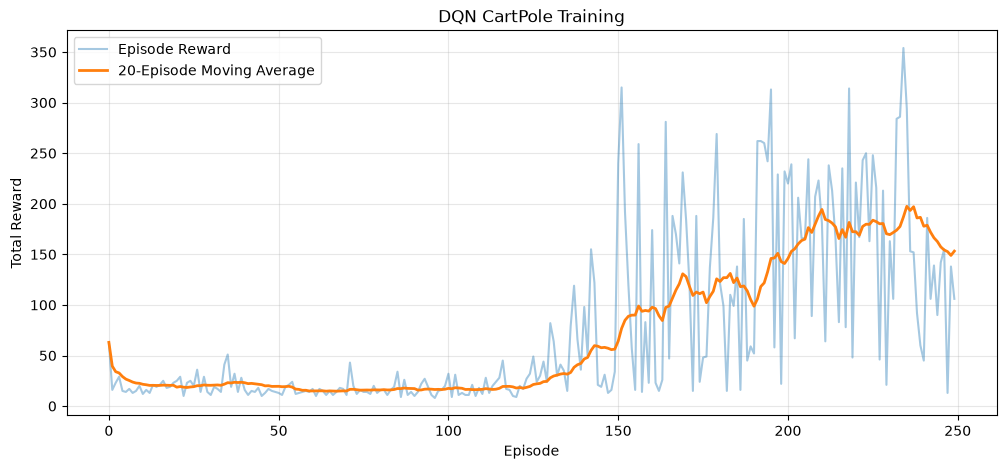

In [11]:
# 최근 20개 에피소드 이동평균
moving_avg = [
    np.mean(episode_rewards[max(0, i - 19):i + 1])
    for i in range(len(episode_rewards))
]

plt.figure(figsize=(12, 5))

plt.plot(
    episode_rewards,
    label="Episode Reward",
    alpha=0.4
)

plt.plot(
    moving_avg,
    label="20-Episode Moving Average",
    linewidth=2
)

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("DQN CartPole Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


___

In [12]:
from torch.distributions import Categorical, Normal

In [13]:
# 위 내용을 함수로 만든거
def discounted_returns(rewards,gamma=0.99):
    out=[]; running=0.0
    for r in reversed(rewards):
        running=float(r)+gamma*running
        out.append(running)
    return list(reversed(out))
print('예시:',discounted_returns([1,1,1],gamma=0.9))

예시: [2.71, 1.9, 1.0]


In [14]:
class PolicyNet(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64),  # 입력 4개(상태) → 은닉층 뉴런 64개
            nn.Tanh(),               # 활성화 함수: 출력값을 -1 ~ 1 범위로 변환
            nn.Linear(64, n_actions) # 은닉층 64개 → 행동 2개의 로짓(Logit) 출력
        )

    def forward(self, x):
        return self.net(x)  # 행동별 로짓 반환 (아직 확률이 아님)

```
def train_reinforce(episodes=250, seed=2026, gamma=0.99, lr=1e-3):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    net = PolicyNet().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    scores = []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        logps = []
        rewards = []
        for t in range(500):
            pass
"""
    1. tensor로 저장
    2. Categorical 사용
    3. sample 뽑기
    4. 4개의 상태 저장
    5. 학습
"""

    env.close()
    return net, scores
```

In [15]:
def train_reinforce(episodes=250, seed=2026, gamma=0.99, lr=1e-3):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')

    net = PolicyNet().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    scores = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)

        logps = []    # 선택한 행동의 로그 확률 저장
        rewards = []  # 매 스텝에서 받은 보상 저장

        for t in range(500):
            # 1. 현재 상태 4개를 (1, 4) 텐서로 변환
            x = torch.as_tensor(
                state, dtype=torch.float32, device=DEVICE
            ).unsqueeze(0)

            # 2. 신경망이 행동별 로짓 출력
            logits = net(x)

            # 3. 로짓을 확률분포로 변환하고 행동 샘플링
            dist = torch.distributions.Categorical(logits=logits)
            action = dist.sample()

            # 선택한 행동의 로그 확률 저장 (역전파에 사용)
            logps.append(dist.log_prob(action).squeeze())

            # 4. 행동 실행 후 다음 상태와 보상 확인
            state, reward, terminated, truncated, _ = env.step(action.item())
            rewards.append(reward)

            if terminated or truncated:
                break

        # 5. 에피소드 종료 후 각 시점의 할인 누적 보상 계산
        returns = discounted_returns(rewards, gamma)

        # 6. Policy Gradient 손실 계산
        G = torch.tensor(returns, dtype=torch.float32, device=DEVICE)
        logps_tensor = torch.stack(logps)

        loss = -(logps_tensor * G).sum()

        # 7. 신경망 가중치 업데이트
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scores.append(sum(rewards))

        if (ep + 1) % 50 == 0:
            print(f"{ep+1:3d}회 | 최근 20회 평균 보상: {np.mean(scores[-20:]):.1f}")

    env.close()
    return net, scores

 50회 | 최근 20회 평균 보상: 22.6
100회 | 최근 20회 평균 보상: 45.1
150회 | 최근 20회 평균 보상: 46.0
200회 | 최근 20회 평균 보상: 56.5
250회 | 최근 20회 평균 보상: 142.8


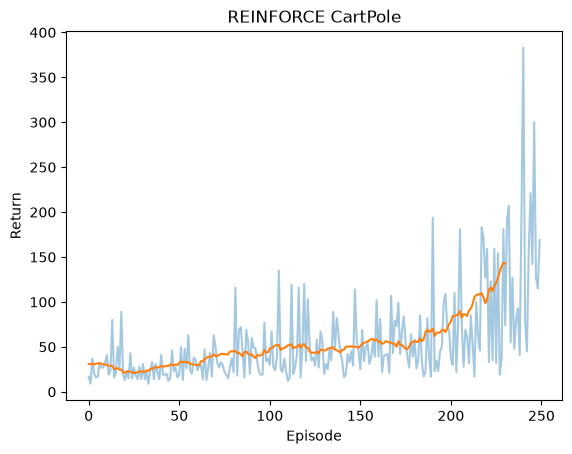

In [16]:
reinforce_model,reinforce_scores=train_reinforce(episodes=250)
plt.plot(reinforce_scores,alpha=.4)
if len(reinforce_scores)>=20:plt.plot(np.convolve(reinforce_scores,np.ones(20)/20,mode='valid'))
plt.title('REINFORCE CartPole');plt.xlabel('Episode');plt.ylabel('Return');plt.show()

___

In [17]:
# TD오차 구하는 함수 = 그냥 예제용으로 쓴거임
def td_error(value, reward, next_value, gamma=0.9, done=False):
    target = reward + gamma * (1 - int(done)) * next_value
    delta = target - value
    return target, delta

cases = [
    ("예상보다 좋음", 4, 1, 6, 0.9, False),
    ("예상보다 나쁨", 5, 2, 4, 0.5, False),
    ("종료 상태", 4, 1, 100, 0.9, True),
]
for name, v, r, next_v, gamma, done in cases:
    target, delta = td_error(v, r, next_v, gamma, done)
    print(f"{name}: TD 목표={target:.2f}, 현재 예측={v:.2f}, δ={delta:+.2f}")

예상보다 좋음: TD 목표=6.40, 현재 예측=4.00, δ=+2.40
예상보다 나쁨: TD 목표=4.00, 현재 예측=5.00, δ=-1.00
종료 상태: TD 목표=1.00, 현재 예측=4.00, δ=-3.00


In [18]:

# Actor-Critic 신경망 정의
# 하나의 상태(State)를 입력받아 다음 두 가지 결과를 출력하는 모델
# 1. Actor: 각 행동의 선택 점수(logits)
# 2. Critic: 현재 상태의 가치 V(s)

class ActorCriticNet(nn.Module):

    # 신경망의 구조를 처음 설정하는 초기화 함수
    # obs_dim=4   : 입력 상태를 구성하는 숫자의 개수 (CartPole은 4개)
    # n_actions=2 : 선택 가능한 행동의 개수 (CartPole은 왼쪽/오른쪽 2개)
    def __init__(self, obs_dim=4, n_actions=2):

        # 부모 클래스(nn.Module)의 초기화 기능 실행 : PyTorch가 신경망의 가중치와 계층을 관리할 수 있도록 함
        super().__init__()

        # Actor와 Critic이 공통으로 사용하는 신경망 : 입력된 상태를 학습에 사용할 특징으로 변환
        self.body = nn.Sequential(

            # 입력 숫자 4개를 받아 특징값 128개로 변환 -> 128은 은닉층의 뉴런 개수이며, 직접 설정한 값
            nn.Linear(obs_dim, 128),

            # 활성화 함수: -1 ~ 1 범위로 출력값을 변환 (신경망이 비선형 관계를 학습할 수 있도록 함)
            nn.Tanh()
        )

        # Actor 출력층
        # 공통 특징값 128개를 받아 행동별 점수 2개 출력, 이 값은 확률이 아닌 logits(원시 점수)
        self.actor = nn.Linear(128, n_actions)

        # Critic 출력층
        # 공통 특징값 128개를 받아 상태 가치 V(s) 1개 출력
        self.critic = nn.Linear(128, 1)

    # 신경망에 입력값이 들어왔을 때 실행되는 순전파 함수
    # x: 환경에서 관측한 현재 상태
    def forward(self, x):

        # 현재 상태를 공통 신경망에 통과시켜 특징 추출  예: (4,) → (128,)
        h = self.body(x)

        # Actor: 행동별 점수 출력 → (2,)
        # Critic: 상태 가치 출력 → (1,)
        # squeeze(-1): Critic 출력의 마지막 크기 1인 차원 제거 예: (1,) → ()
        return self.actor(h), self.critic(h).squeeze(-1)


In [19]:
ac_demo = ActorCriticNet().to(DEVICE)
lg, val = ac_demo(state_demo)

print("Actor logits:", lg.shape)
print("Critic V(s):", val.shape)

NameError: name 'state_demo' is not defined

In [ ]:
import torch.nn.functional as F


### **4-2. REINFORCE CartPole을 Actor-Critic으로 변경해보기**
- REINFORCE는 에피소드가 끝난 뒤 할인 리턴을 계산했지만, Actor-Critic은 매 스템 TD오차로 업데이트함
- PolicyNet 대신 Actor의 logits 2개 + Critic의 상태 가치 1개를 출력하는 ActorCriticNet 사용
- 학습 보상 곡선을 REINFORCE와 비교함

#### 문제는
1. ActorCriticNet을 이용해 행동 확률과 상태 가치 V(s)를 출력
2. Categorical(logits=logits)로 행동을 샘플링하고 환경에서 한 스탭을 실행
3. 250개 에피소드동안 학습하고, 각 에피소드 보상과 최근 20회 이동평균을 그림
4. 이미 학습한 reinforce_scores와 두 학습 곡선 비교


In [ ]:

# Actor-Critic: 매 스텝 TD 오차를 이용해 Actor와 Critic을 학습하는 함수
def train_actor_critic(episodes=250, seed=2026, gamma=0.99, lr=1e-3):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')

    # Actor는 행동별 logits, Critic은 상태 가치 V(s)를 출력
    net = ActorCriticNet().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    scores = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)
        total_reward = 0.0

        for t in range(500):
            x = torch.as_tensor(
                state, dtype=torch.float32, device=DEVICE
            ).unsqueeze(0)

            logits, value = net(x)

            # logits는 확률이 아니므로 Categorical로 행동 확률분포를 만듦
            dist = Categorical(logits=logits)
            action = dist.sample()
            log_prob = dist.log_prob(action).squeeze()

            next_state, reward, terminated, truncated, _ = env.step(
                int(action.item())
            )
            episode_done = terminated or truncated

            # 다음 상태 가치는 TD 목표값 계산에만 사용하므로 기울기 추적 X
            with torch.no_grad():
                next_x = torch.as_tensor(
                    next_state, dtype=torch.float32, device=DEVICE
                ).unsqueeze(0)

                _, next_value = net(next_x)

                td_target = (
                    reward
                    + gamma * (1 - float(terminated)) * next_value
                )

            # TD 오차 = 새로 계산한 목표값 - Critic의 현재 예측값
            delta = td_target - value

            # Actor: TD 오차가 양수면 선택한 행동의 확률을 높이는 방향
            # detach()는 왜 쓸까? Actor Loss가 Critic 쪽으로 역전파되지 않도록!
            actor_loss = -log_prob * delta.detach().squeeze()

            # Critic: 현재 가치 V(s)를 TD 목표값에 가깝게 학습
            critic_loss = delta.pow(2).mean()

            loss = actor_loss + critic_loss

            # Loss 계산만으로는 학습되지 않음 → 기울기 계산 후 가중치 수정
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            state = next_state
            total_reward += float(reward)

            if episode_done:
                break

        scores.append(total_reward)

        if (ep + 1) % 30 == 0:
            print(
                f'Actor-Critic {ep+1}/{episodes} | '
                f'최근 20회 평균 {np.mean(scores[-20:]):.1f}'
            )

    env.close()
    return net, scores


___
# **5. Actor-Critic을 이용한 달 착륙 AI 개발**

Gymnasium을 이용해 우주선이 스스로 엔진을 제어하고 안전하게 착륙하도록 학습하는 강화학습 시스템 개발

### **5-1. 프로젝트 시나리오**
- 달 표면에 착륙할 우주선은 처음엔 엔진을 언제 사용해야하는지 알 수 없음
- 너무 빠르게 하강하면 추락하고, 좌우 균형을 잡지 못하면 착륙 지점을 벗어날 수 있음
    - 우주선의 현재 위치와 속도를 분석
    - 우주선읙 기울기와 회전 속도 확인
    - 엔진을 사용하거나 사용하지 않는 행동을 선택
    - 행동 결과로 받은 보상을 이용해 Actor와 Critic을 학습
    - 반복 학습을 통해 안전한 착륙 시도
- 그래서 우주선은 시행착오를 통해 안전하게 착륙하는 방법을 학습해야 함

### **5-2. 개발 환경**
- Gymnasium의 LunarLander-v3 환경 사용
```
python -m pip install "gymnasium[box2d]"
```

### **5-3. 상태 데이터**
- LunarLander-v3 매 스텝마다 8개의 숫자로 구성된 상태 벡터를 반환
```
인덱스 기준 값 설명

0 : 착륙 지점을 기준으로 한 좌우 위치
1 : 착륙 지점을 기준으로 한 높이
2 : 좌우 속도
3 : 수직 속도
4 : 우주선 기울기
5 : 우주선 회전 속도
6 : 왼쪽 착륙 다리가 지면에 닿았는지 여부 (0: 닿지 않음, 1: 닿았음)
7 : 오른쪽 착륙 다리가 지면에 닿았는지 여부 (0: 닿지 않음, 1: 닿았음)

값들은 정규화된 값임
```

### **5-4. 행동 데이터**
```
0: 엔진 사용하지 않음 - 중력에 따라 자연스럽게 이동
1: 왼쪽 보조 엔진 - 우주선의 자세와 이동에 영향
2: 주 엔진 - 주로 하강 속도를 제어하는데 사용
3: 오른쪽 보조 엔진 - 우주선의 자세와 이동에 영향
```

### **5. 보상 데이터**
- LunarLander는 단순히 착륙 성공과 실패만 평가하지 않음
- 착륙 지점까지의 거리, 속도, 기울기, 착륙 다리 접촉, 엔진 사용량 등을 함께 고려
    - 착륙 시점에 가까워질 때
    - 이동 속도가 줄어들 때
    - 우주선의 기울기가 커질때
    - 착륙 다리가 지면에 닿았을 때
    - 엔진 사용량이 적을 때
    - 보조 엔진 사용량이 적을 때
    - 추락할 때: -100
    - 안전하게 착륙할 때: +100

In [ ]:
import gymnasium as gym

env = gym.make("LunarLander-v3")

# 게임 시작 시 현재 상태 가져오기
state, info = env.reset(seed=2026)

print("현재 상태:", state)
print("상태 개수:", len(state))

# 행동 0: 엔진 사용하지 않기
next_state, reward, terminated, truncated, info = env.step(0)

print("다음 상태:", next_state)
print("보상:", reward)
print("종료 여부:", terminated or truncated)

env.close()

현재 상태: [ 0.00216942  1.4164361   0.21971932  0.24514917 -0.00250698 -0.04976973
  0.          0.        ]
상태 개수: 8
다음 상태: [ 0.00433865  1.421374    0.21942255  0.21945246 -0.00496627 -0.04918928
  0.          0.        ]
보상: 1.146953124739781
종료 여부: False


In [ ]:
print('상태 공간:', env.observation_space)
print('행동 공간:', env.action_space)
print('상태 shape:', state.shape)

In [ ]:
# CartPole
net = ActorCriticNet(obs_dim=4, n_actions=2)

# LunarLander
net = ActorCriticNet(obs_dim=8, n_actions=4)